<a href="https://colab.research.google.com/github/metekoksal/GROUP45_CENG313/blob/main/assignment1_eda_baseline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Assignment 1: EDA and Baseline Models

**Grup 45 – CENG313 Veri Bilimine Giriş**

Yarışma: [Recod.ai/LUC – Scientific Image Forgery Detection](https://www.kaggle.com/competitions/recodai-luc-scientific-image-forgery-detection)

Github: https://github.com/metekoksal/GROUP45_CENG313


## 1. Problem Tanımı

### 1.1 Görev
Bu yarışma, biyomedikal araştırma makalelerinde yer alan görsellerdeki **copy-move sahteciliğini** (bir görsel bölgesinin aynı görselin başka bir yerine kopyalanıp yapıştırılması) tespit etmeyi ve bölgeleri **piksel düzeyinde segmente etmeyi** amaçlar. Bilimsel makalelerde görsel manipülasyonu, geri çekilen (retracted) makalelerin başlıca nedenlerinden biridir; bu yüzden otomatik tespit araştırma dürüstlüğü açısından önem taşır.

Problem iki parçalıdır:
1. **Sınıflandırma:** Görsel *authentic* (orijinal) mi, *forged* (sahte) mi?
2. **Segmentasyon:** Görsel sahteyse, kopyalanan bölgelerin maskesi (instance bazında) nedir?

Bu nedenle problem instance segmentasyonu içeren bir tespit problemidir. Bir görselde birden fazla sahte bölge (instance) olabilir.

### 1.2 Hedef değişken
- **Girdi:** Tek bir RGB görsel (boyutlar 64 ile 3888 piksel arasında değişir).
- **Çıktı:** Authentic görsel için "authentic" etiketi, sahte görsel için her sahte instance'a ait ayrı bir ikili maske üretilir.
- **Eğitim etiketi:** Her sahte görsel için piksel düzeyinde ground-truth maskeleri (`.npy`, instance sayısı kadar kanal). Authentic görsellerin maskesi yoktur. Görsel düzeyinde etiket (`label`: 0 = authentic, 1 = forged) maskenin varlığından türetilmiştir.

### 1.3 Değerlendirme metriği (oF1)
Yarışma, **instance düzeyinde F1 skorunu (oF1)** görsel bazında hesaplayıp tüm görseller üzerinden ortalar. Bu projedeki yorumlarımızın dayandığı temel davranışlar:

- **Authentic görsel:** Model "authentic" derse skor 1, herhangi bir maske üretirse skor 0 olur. Yani authentic bir görselde tek bir yanlış alarm o görselin skorunu sıfırlar.
- **Sahte görsel:** Model "authentic" derse skor 0 olur. Maske üretirse, tahmin edilen instance'lar ground-truth instance'larla eşleştirilir ve eşleşmelere göre bir F1 skoru hesaplanır.
- **Sonuç:** Yüksek skor için hem sahte görsellerde yüksek recall hem de authentic görsellerde sıfıra yakın yanlış alarm gerekir. Hiçbir şey öğrenmeyen "hepsi authentic" tahmini bile authentic oranına eşit (≈0.46) skor alır, bu yüzden bu değer bizim alt sınır baseline'ımızdır.

Piksel accuracy bu problem için anlamlı değildir, çünkü sahte bölgeler görselin çok küçük bir kısmını kaplar.

### 1.4 Değerlendirme stratejimiz
Yarışmanın test etiketleri herkese açık olmadığından, modelleri eğitim verisinden ayırdığımız **validation seti** üzerinde, resmi oF1 metriğinin kendi implementasyonumuzla ölçüyoruz (utils.py). Ayar yapılan ve rapor edilen yarılar birbirinden ayrılmıştır.

##0. Setup

In [ ]:
import os, sys
if not os.path.exists("/content/GROUP45_CENG313"):
   !git clone -b main https://github.com/metekoksal/GROUP45_CENG313.git
%cd /content/GROUP45_CENG313
!git pull origin main
!pip install -q -r requirements.txt
sys.path.append("/content/GROUP45_CENG313")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from PIL import Image

from src.data import *
from src.utils import *
from src.models import *


Cloning into 'GROUP45_CENG313'...
remote: Enumerating objects: 124, done.
remote: Counting objects: 100% (124/124), done.
remote: Compressing objects: 100% (91/91), done.
remote: Total 124 (delta 59), reused 84 (delta 24), pack-reused 0 (from 0)
Receiving objects: 100% (124/124), 24.32 KiB | 2.21 MiB/s, done.
Resolving deltas: 100% (59/59), done.
/content/GROUP45_CENG313
From https://github.com/metekoksal/GROUP45_CENG313
 * branch            main       -> FETCH_HEAD
Already up to date.


Import data files from Kaggle

In [ ]:
import os
from google.colab import userdata

if not os.path.exists("/content/data/train_images"):
    os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN")
    !pip install -q --upgrade kaggle
    !kaggle competitions download -c recodai-luc-scientific-image-forgery-detection -p /content/data
    !unzip -q /content/data/*.zip -d /content/data

100% 4.85G/4.85G [01:07<00:00, 77.3MB/s]



## 1. Veri Yükleme ve Sınıf Dağılımı

In [ ]:
df = build_train_df()
print(df.shape)
print(df.label.value_counts())
df.head()

(5128, 4)
label
1    2751
0    2377
Name: count, dtype: int64


,case_id,path,label,mask_path
0,10,/content/data/train_images/authentic/10.png,0,None
1,10015,/content/data/train_images/authentic/10015.png,0,None
2,10017,/content/data/train_images/authentic/10017.png,0,None
3,10030,/content/data/train_images/authentic/10030.png,0,None
4,10070,/content/data/train_images/authentic/10070.png,0,None


Eğitim verisi 5128 görselden oluşuyor: 2751 sahte (forged), 2377 authentic.
Sınıflar görsel düzeyinde neredeyse dengeli (%54 / %46).

## 2. EDA

In [ ]:
size_df = image_sizes(df)
forg = mask_stats(df)

100%|██████████| 2751/2751 [00:05<00:00, 521.71it/s]


##2.1. Görsel Boyutları

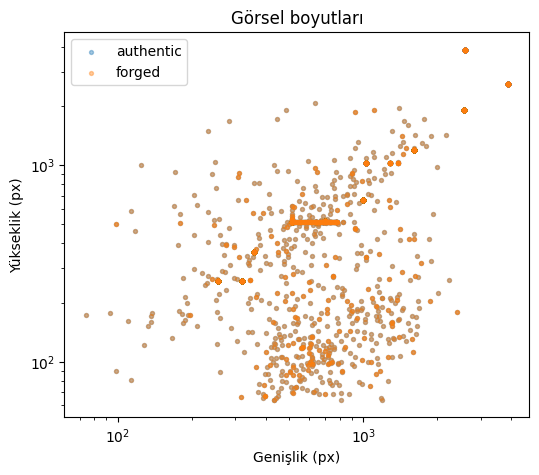

w                                                         h  \
        count   mean    std   min    25%    50%     75%     max   count   
label                                                                     
0      2377.0  933.0  742.0  74.0  381.0  696.0  1024.0  3888.0  2377.0   
1      2751.0  930.0  718.0  74.0  415.0  696.0  1076.0  3888.0  2751.0   

                                                        
        mean    std   min    25%    50%    75%     max  
label                                                   
0      698.0  694.0  64.0  256.0  512.0  666.0  3888.0  
1      688.0  666.0  64.0  256.0  512.0  810.0  3888.0

In [ ]:
plot_size_scatter(size_df)
plt.show()

size_df.groupby("label")[["w", "h"]].describe().round(0)

**Gözlem:** Görsel boyutları 64 ile 3888 piksel arasında değişiyor; en sık boyutlar
1000×666, 256×256 ve 1600×1200. Authentic ve forged görsellerin boyut dağılımları
[benzer / farklı].

**Sonuç:** Tek bir sabit boyut yok, bu yüzden görselleri 512×512'ye yeniden
boyutlandıracağız (maskede nearest-neighbor interpolation ile).

##2.2. Maske alanı

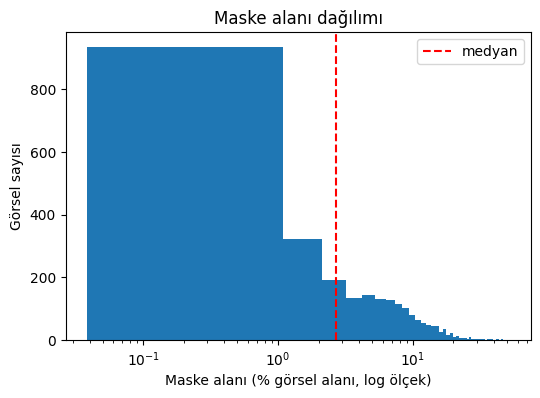

,area_ratio
count,2751.0000
mean,0.0552
std,0.0692
min,0.0004
25%,0.0075
50%,0.0271
75%,0.0809
max,0.5227


In [ ]:
plot_area_ratio(forg)
plt.show()

forg["area_ratio"].describe().round(4)

**Gözlem:** Maske alanının medyanı görselin %2.7'si, ortalaması %5.5, minimumu %0.04.
Dağılım sağa çarpık: çoğu maske çok küçük, az sayıda maske büyük.

**Sonuç:** Pozitif pikseller çok az olduğundan piksel accuracy anlamsız. Eğitimde
BCE + Dice loss kullanacağız; küçük bileşen filtresini dikkatli seçeceğiz.

##2.3. Instance sayısı

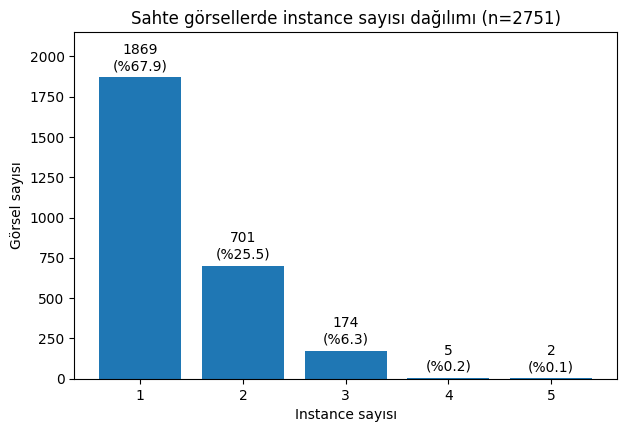

In [ ]:
plot_instance_counts(forg)
plt.show()

**Gözlem:** Sahte görsellerin %68'i tek, %25'i iki, %6'sı üç instance içeriyor; 4 ve 5 instance çok nadir (7 görsel).

**Sonuç:** Tahmin edilen maske connected component'lara ayrılıp her bileşen ayrı instance olarak raporlanmalı.

### 2.4 Örnek görseller

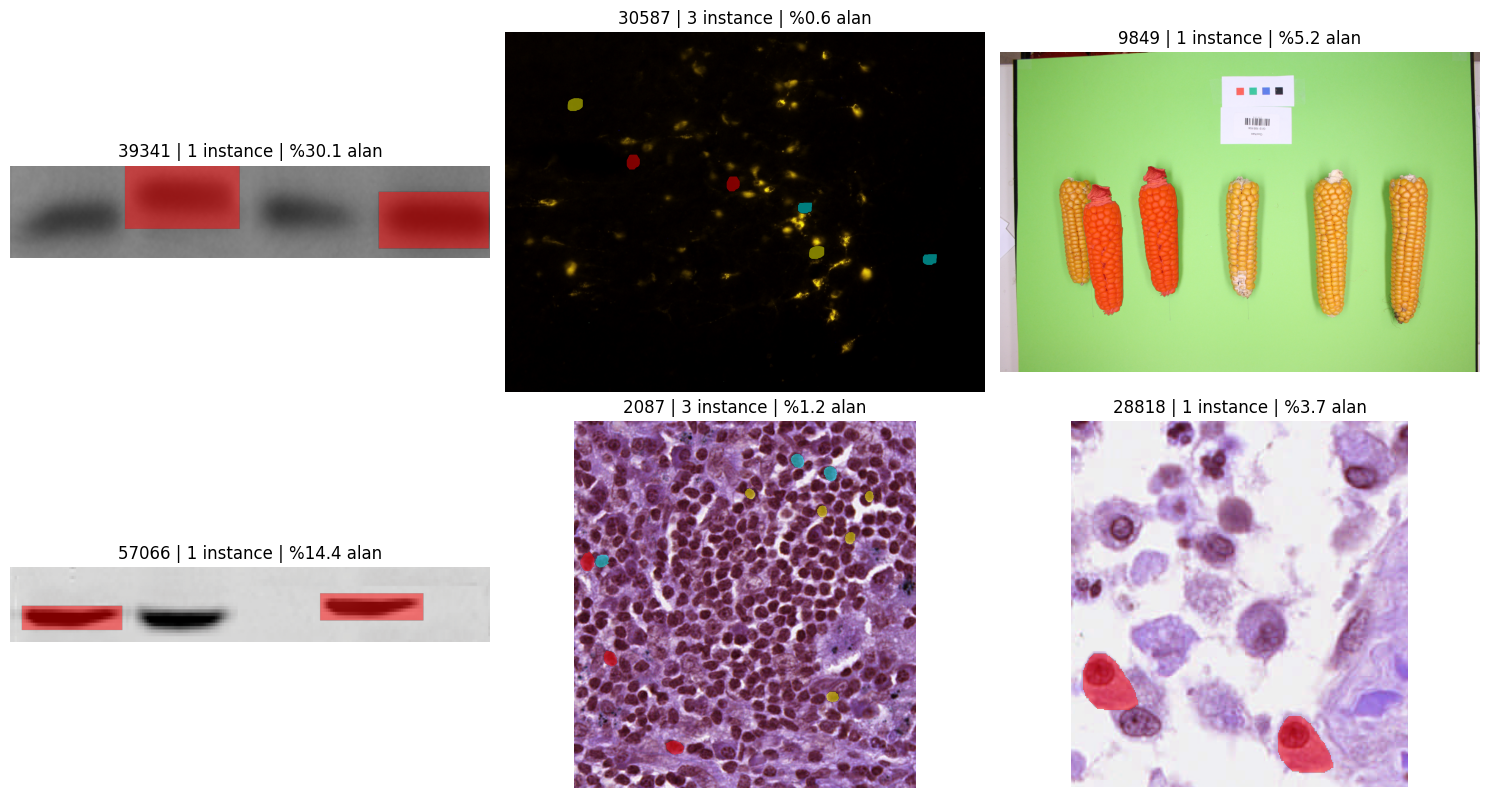

In [ ]:
show_samples(df, n=6, label=1)
plt.show()

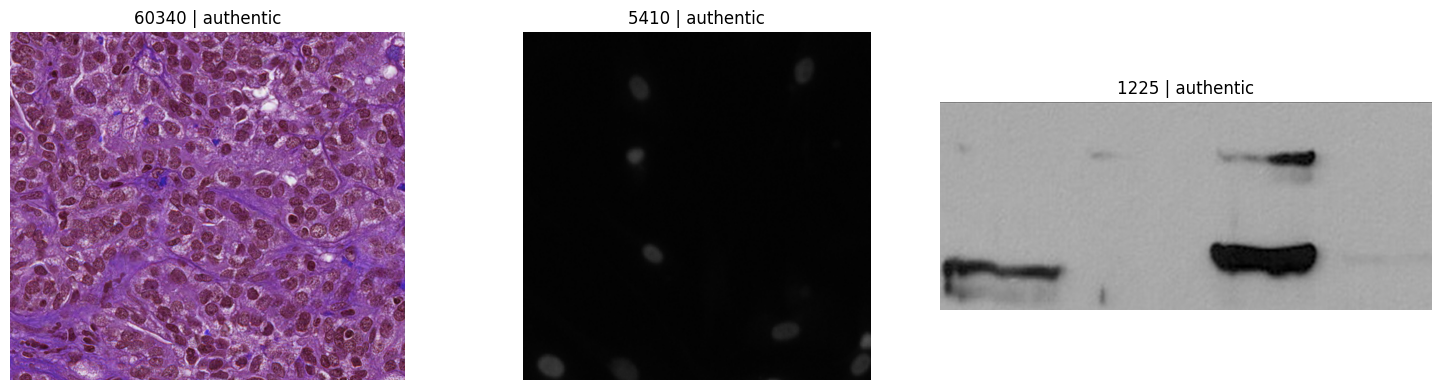

In [ ]:
show_samples(df, n=3, label=0)
plt.show()

### 2.5 En küçük ve en büyük maskeler

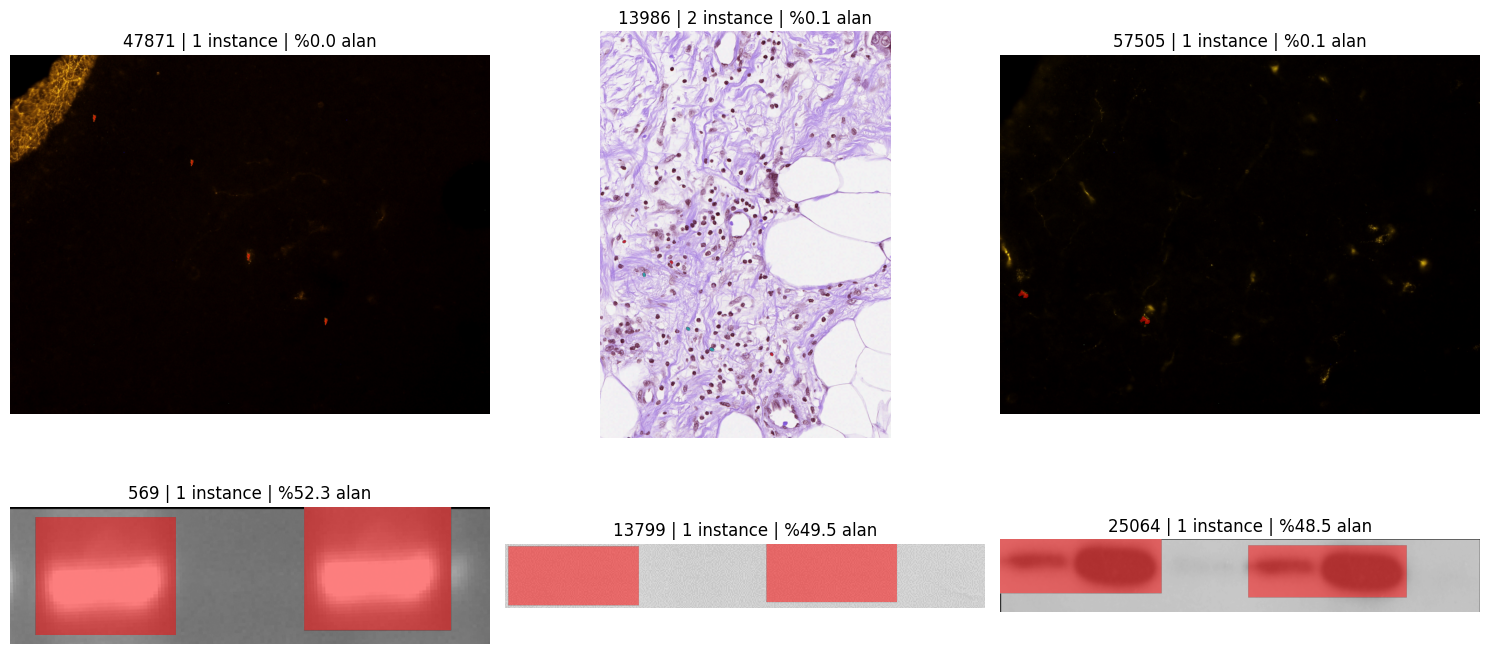

In [ ]:
show_extremes(forg, k=3)
plt.show()

### 2.6 Authentic ve forged boyut karşılaştırması

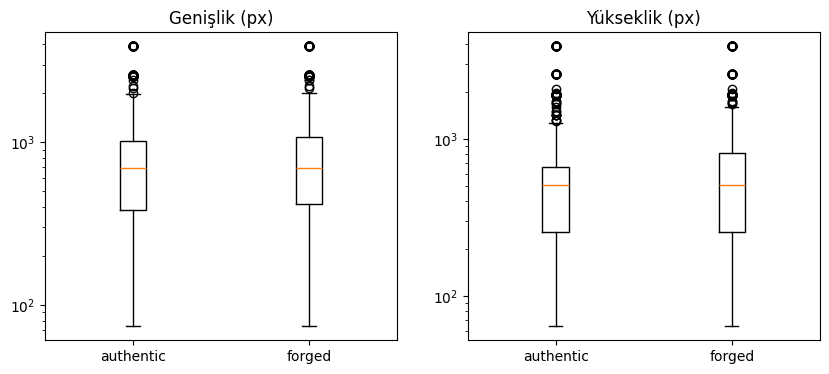

w                                                         h  \
        count   mean    std   min    25%    50%     75%     max   count   
label                                                                     
0      2377.0  933.0  742.0  74.0  381.0  696.0  1024.0  3888.0  2377.0   
1      2751.0  930.0  718.0  74.0  415.0  696.0  1076.0  3888.0  2751.0   

                                                        
        mean    std   min    25%    50%    75%     max  
label                                                   
0      698.0  694.0  64.0  256.0  512.0  666.0  3888.0  
1      688.0  666.0  64.0  256.0  512.0  810.0  3888.0

In [ ]:
plot_size_by_class(size_df)
plt.show()

size_df.groupby("label")[["w", "h"]].describe().round(0)

**Gözlem:** Authentic ve forged görsellerin genişlik ve yükseklik dağılımları büyük ölçüde örtüşüyor. Medyan genişlik iki sınıfta da yaklaşık 700 px, medyan yükseklik yaklaşık 500 px.
Forged görsellerin üst çeyreklik değerleri biraz daha yüksek ancak fark küçük.

**Sonuç:** Görsel boyutu tek başına sınıfı ayırt etmiyor, modelin boyutu kestirme yol olarak öğrenme riski düşük görünüyor. Yine de belirli çözünürlüklerdeki sınıf oranlarına ayrıca bakacağız.

In [ ]:
top_sizes_by_class(size_df)

label,authentic,forged,total,forged_ratio
size,,,,
1000x666,343,343,686,0.50
256x256,290,315,605,0.52
1600x1200,227,303,530,0.57
696x520,116,140,256,0.55
320x256,108,121,229,0.53
512x512,91,108,199,0.54
2568x1912,95,102,197,0.52
360x360,91,105,196,0.54


**Gözlem:** En sık 8 çözünürlükte (toplam 2898 görsel, verinin %56.5'i) sahte oranı 0.50–0.57
arasında; genel orana (0.54) yakın.

**Sonuç:** Çözünürlük sınıf hakkında bilgi taşımıyor, model boyutu kestirme yol olarak
öğrenemez. 512×512 yeniden boyutlandırma güvenle kullanılabilir.

### EDA bulguları özeti
1. 5128 eğitim görseli: 2751 sahte (%54), 2377 authentic (%46); sınıflar dengeli.
2. Boyutlar çok değişken (64-3888 px); 512×512 yeniden boyutlandırma kullanılacak.
3. Maske alanı çok küçük (medyan %2.7); BCE + Dice loss gerekli.
4. Sahte görsellerin %32'sinde birden çok instance var; connected component ile ayrıştırılacak.

## 3. Train/Validation Ayrımı

In [ ]:
train_df, val_df = split_train_val(df)
print(len(train_df), len(val_df))
print("sahte oranı:", train_df.label.mean().round(3), val_df.label.mean().round(3))

4102 1026
sahte oranı: 0.537 0.536


## 4. Baseline Modeller

### 4.1 Baseline 0: Hepsi authentic

In [ ]:
pred = predict_all_authentic(val_df)
acc = (pred == val_df.label.values).mean()
print("Baseline 0 görsel düzeyi accuracy:", round(acc, 3))

score0 = evaluate_df(val_df, lambda row: [])    # hepsine "authentic"
print("Baseline 0, oF1:", round(score0, 3))

Baseline 0 görsel düzeyi accuracy: 0.464


100%|██████████| 1026/1026 [00:00<00:00, 3771.41it/s]

Baseline 0, oF1: 0.464


Her görsele "authentic" demek validation setinde %46.4 accuracy veriyor; bu, authentic görsellerin oranına eşit. Gerçek modellerin bu değeri anlamlı biçimde geçmesi gerekir.

Not: Bu, görsel düzeyi accuracy'dir; yarışma metriği (oF1) maske kalitesini de ölçer ve metrik implementasyonundan sonra bu baseline için yeniden hesaplanacaktır.

Resmi oF1 metriğiyle Baseline 0 skoru 0.464 çıktı; bu, validation'daki authentic görsellerin oranına eşit. Metrik, sahte bir görseli "authentic" bırakmayı 0 puanla cezalandırdığı için bu değer, hiçbir şey öğrenmeyen bir modelin alt sınırıdır.

###Veri yükleyici testi

In [ ]:
ds = ForgeryDataset(train_df, size=512, augment=True)
dl = DataLoader(ds, batch_size=8, shuffle=True, num_workers=2)
b = next(iter(dl))
print("görsel batch:", tuple(b["image"].shape), "| maske batch:", tuple(b["mask"].shape))

görsel batch: (8, 3, 512, 512) | maske batch: (8, 1, 512, 512)


In [ ]:
bad = 0
for r in df[df.label == 1].head(300).itertuples():
    w, h = Image.open(r.path).size
    if load_mask(r.mask_path).shape[1:] != (h, w):
        bad += 1
print("boyutu uyuşmayan maske sayısı:", bad)

boyutu uyuşmayan maske sayısı: 0


Görseller 512×512'ye yeniden boyutlandırıldı ve ImageNet istatistikleriyle normalize edildi. Maskeler nearest interpolation ile aynı boyuta getirildi. Overlay, maskenin yeniden boyutlandırma sonrası da kopyalanan bölgeyle hizalı kaldığını gösteriyor.

### 4.2 Baseline 1: SIFT + RANSAC

In [ ]:
sub = val_df.sample(100, random_state=0)
det = SiftCopyMoveDetector()

s0 = evaluate_df(sub, lambda r: [])
s1, per = evaluate_df(sub, det, return_per_image=True)
is_auth = sub.label.values == 0
print(f"Baseline 0: {s0:.3f} | SIFT: {s1:.3f}")
print(f"authentic skoru: {per[is_auth].mean():.3f} | sahte skoru: {per[~is_auth].mean():.3f}")

100%|██████████| 100/100 [00:31<00:00,  3.20it/s]

Baseline 0: 0.510 | SIFT: 0.631
authentic skoru: 0.961 | sahte skoru: 0.287


**Yöntem:** Eğitim gerektirmeyen klasik bir yaklaşım. Görseldeki SIFT keypoint'leri aynı görselin içinde birbiriyle eşleştirilir, birbirine çok yakın noktalar elenir, Lowe ratio testi uygulanır. Kalan eşleşmelere RANSAC ile tek bir geometrik dönüşüm (öteleme, dönme, ölçek) uydurulur. Dönüşüme uyan eşleşme sayısı `min_inliers` eşiğinden azsa görsel "authentic" kabul edilir, aksi halde bu noktaların çevresinden maske üretilir. Birden çok kopyalama için işlem tekrarlanır (en fazla 3 instance).

**Parametre seçimi:** `min_inliers` ve `ratio` değerleri validation setini kullanmadan, train setinden alınan 100 görsellik rastgele bir örnek üzerinde seçildi.

In [ ]:
tune = train_df.sample(100, random_state=1)
is_auth = tune.label.values == 0

rows = []
for mi in [4, 6, 8, 10]:
    det = SiftCopyMoveDetector(min_inliers=mi)
    total, per = evaluate_df(tune, det, return_per_image=True)
    rows.append({"min_inliers": mi, "genel": total,
                 "authentic": per[is_auth].mean(), "sahte": per[~is_auth].mean()})

pd.DataFrame(rows).round(3)

100%|██████████| 100/100 [00:26<00:00,  3.77it/s]


,min_inliers,genel,authentic,sahte
0,4,0.338,0.722,0.122
1,6,0.380,0.917,0.079
2,8,0.402,0.972,0.081
3,10,0.409,1.000,0.076


In [ ]:
det = SiftCopyMoveDetector(min_inliers=10)
forged = tune[tune.label == 1]
_, per = evaluate_df(forged, det, return_per_image=True)
n_pred = [len(det(r)) for r in forged.itertuples()]

print("0 skorlu sahte oranı:", round((per == 0).mean(), 2))
print("bulunanlarda ortalama skor:", round(per[per > 0].mean(), 2))
print("hiç maske üretilmeyen sahte oranı:", round(np.mean(np.array(n_pred) == 0), 2))

100%|██████████| 64/64 [00:15<00:00,  4.13it/s]


0 skorlu sahte oranı: 0.91
bulunanlarda ortalama skor: 0.82
hiç maske üretilmeyen sahte oranı: 0.91


**Hata analizi:** Train örneğinde sahte görsellerin %91'inde SIFT dedektörü hiçbir
şey yakalayamadı, yakaladığı görsellerde ortalama oF1 0.82. Yani sorun maske kalitesi
değil, eşleşme bulma (recall). Biyomedikal görsellerde (blot, mikroskopi) düz ve
düşük dokulu alanlar az sayıda ayırt edici keypoint ürettiği, kopyalanan bölgeler
ise yeniden ölçekleme, bulanıklaştırma ve sıkıştırmayla değiştirildiği için
descriptor eşleşmesi zayıf kalıyor. Eşik gevşetildikçe authentic görsellerde yanlış
alarm arttığı için (authentic skoru 1.00 → 0.72) bir recall/precision dengesi var.

In [ ]:
tune = train_df.sample(100, random_state=1)     # eski hücreyle aynı örnek, sonuçlar karşılaştırılabilir
is_auth = tune.label.values == 0

configs = [
    dict(ratio=0.75),
    dict(ratio=0.85),
    dict(ratio=0.75, min_dist=10),
    dict(ratio=0.75, n_features=6000),
]
rows = []
for cfg in configs:
    d = SiftCopyMoveDetector(min_inliers=10, **cfg)
    total, per = evaluate_df(tune, d, return_per_image=True)
    rows.append({**cfg, "genel": total,
                 "authentic": per[is_auth].mean(), "sahte": per[~is_auth].mean()})
    print(rows[-1])
print(pd.DataFrame(rows).round(3).to_string(index=False))

100%|██████████| 100/100 [00:26<00:00,  3.74it/s]


{'ratio': 0.75, 'genel': 0.3979806595409231, 'authentic': np.float64(0.9722222222222222), 'sahte': np.float64(0.0749697805326924)}


100%|██████████| 100/100 [00:26<00:00,  3.73it/s]


{'ratio': 0.85, 'genel': 0.3391164339864426, 'authentic': np.float64(0.8333333333333334), 'sahte': np.float64(0.06111942810381653)}


100%|██████████| 100/100 [00:26<00:00,  3.71it/s]


{'ratio': 0.75, 'min_dist': 10, 'genel': 0.38797643256603875, 'authentic': np.float64(0.9444444444444444), 'sahte': np.float64(0.07496317588443566)}


100%|██████████| 100/100 [00:35<00:00,  2.81it/s]

{'ratio': 0.75, 'n_features': 6000, 'genel': 0.3881188117594369, 'authentic': np.float64(0.9444444444444444), 'sahte': np.float64(0.07518564337412013)}
 ratio  genel  authentic  sahte  min_dist  n_features
  0.75  0.398      0.972  0.075       NaN         NaN
  0.85  0.339      0.833  0.061       NaN         NaN
  0.75  0.388      0.944  0.075      10.0         NaN
  0.75  0.388      0.944  0.075       NaN      6000.0


**Parametre seçimi:** Train'den alınan 100 görsellik örnekte min_inliers ∈ {4, 6, 8, 10} ve ratio ∈ {0.6, 0.75, 0.85} (ayrıca min_dist ve n_features) denendi. En yüksek genel skor min_inliers=10, ratio=0.6 ile elde edildi. Eşikleri gevşetmek sahte görsellerde skoru anlamlı biçimde artırmadı (≈0.08), authentic görsellerde ise yanlış alarmlar nedeniyle skoru düşürdü (1.00 → 0.72).

In [ ]:
det = SiftCopyMoveDetector(min_inliers=10)      # ratio=0.6 varsayılan
s1, per1 = evaluate_df(val_df, det, return_per_image=True)
is_auth_val = val_df.label.values == 0

print(f"oF1: {s1:.3f}  (Baseline 0: {score0:.3f})")
print(f"authentic: {per1[is_auth_val].mean():.3f} | sahte: {per1[~is_auth_val].mean():.3f}")
print(f"sahtelerde 0 skorlu oran: {(per1[~is_auth_val] == 0).mean():.2f}")

100%|██████████| 1026/1026 [04:29<00:00,  3.80it/s]

oF1: 0.534  (Baseline 0: 0.464)
authentic: 0.960 | sahte: 0.165
sahtelerde 0 skorlu oran: 0.79


**Sonuç:** Validation setinde (1026 görsel) SIFT + RANSAC baseline'ı oF1 = 0.534 aldı (Baseline 0: 0.464). Authentic görsellerde skor 0.960, sahte görsellerde 0.165, sahte görsellerin %79'unda hiçbir bölge doğru tespit edilemedi.

**Yorum:** Yöntem authentic görselleri büyük ölçüde koruyor (yanlış alarm = %4) ve Baseline 0'a göre yaklaşık 0.07 puan kazanç sağlıyor; bu kazanç sahte görsellerin küçük bir kısmının doğru bulunmasından geliyor. Bulunan sahtelerde maske kalitesi yüksek (yaklaşık 0.8), asıl sınır eşleşme bulma oranı. Parametre ayarı için kullanılan 100 görsellik örnek küçük olduğundan ayarlar arasındaki farklar istatistiksel olarak anlamlı sayılmamalıdır.



### 4.3 Baseline 2: U-Net

In [ ]:
import time
print("GPU:", torch.cuda.is_available())

model = build_unet()
t0 = time.time()
history = fit(model, train_df.sample(200, random_state=0),
              val_df.sample(100, random_state=0), epochs=1)
dt = time.time() - t0

print(f"süre: {dt:.0f} sn (200 train + 100 val görsel)")
# süre tahmini (gpu'da ~40dk, cpu'da AŞIRI uzun.)
# token yetiyorsa Runtime > Change Runtime Type > GPU seçin.
# token yoksa releases kısmında eğitilmiş checkpoint var
per_img = dt / 300
print(f"görsel başına ≈ {per_img:.2f} sn")
print(f"tam epoch tahmini (4102 train + 1026 val): ≈ {per_img * 5128 / 60:.0f} dk")

GPU: True


config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 87.3MB            

model.safetensors: downloading bytes:           |  0.00B            

epoch 1/1 | train 0.8545 | val 0.7467
süre: 19 sn (200 train + 100 val görsel)
görsel başına ≈ 0.06 sn
tam epoch tahmini (4102 train + 1026 val): ≈ 5 dk


###Training (GPU ile yaklaşık 40 dk)

In [ ]:
CKPT = "/content/checkpoints/unet_resnet34.pth"
#CKPT = "/content/unet_resnet34.pth"  # manuel olarak yüklendiyse üstü commentlayıp bunu uncommentlayın
model = build_unet()

if os.path.exists(CKPT):
    model.load_state_dict(torch.load(CKPT, map_location="cpu"))
    print("Kayıtlı ağırlık yüklendi, eğitim atlandı.")
else:
    history = fit(model, train_df, val_df, epochs=8, save_path=CKPT)

#from google.colab import files
#files.download(CKPT)      # tarayıcıdan bilgisayarına indirir, session kapanırsa 40dklık eğitim kaybolmasın diye.

epoch 1/8 | train 0.5515 | val 0.5159


epoch 2/8 | train 0.4952 | val 0.4803


epoch 3/8 | train 0.4787 | val 0.4743


epoch 4/8 | train 0.4686 | val 0.4642


epoch 5/8 | train 0.4612 | val 0.4603


epoch 6/8 | train 0.4586 | val 0.4650


epoch 7/8 | train 0.4726 | val 0.5164


epoch 8/8 | train 0.4855 | val 0.4983


###Loss Eğrisi

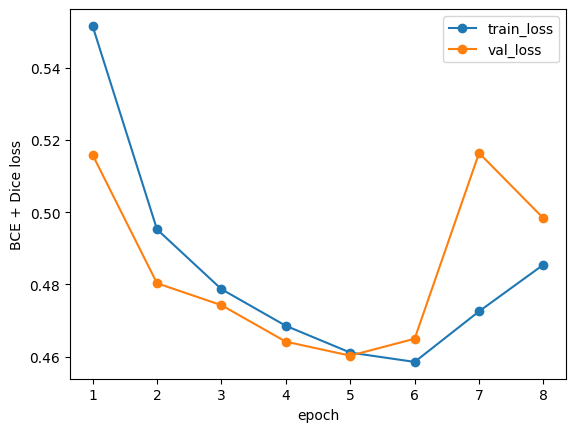

In [ ]:
# Train çalıştırıldıysa. manuel yüklemede çalışmaz
h = pd.DataFrame(history)
h.plot(x="epoch", y=["train_loss", "val_loss"], marker="o")
plt.ylabel("BCE + Dice loss"); plt.show()

U-Net (ResNet34 encoder, ImageNet ön-eğitimli) 8 epoch eğitildi (BCE+Dice loss, AdamW, lr=3e-4, 512×512 girdi, flip augmentation). İlk 5 epoch'ta hem train hem validation loss düştü (train 0.55 → 0.46, val 0.51 → 0.45). Epoch 6'dan sonra
train loss yükseldi ve validation loss dalgalandı, bu ezberleme değil, eğitimin kararsızlaşmasıdır (sabit öğrenme oranı olası bir neden). En düşük validation loss'lu epoch (5) checkpoint olarak seçildi.

### 4.4 U-Net çıktısının son işlenmesi

In [ ]:
model = build_unet(pretrained=False)
model.load_state_dict(torch.load(CKPT, map_location="cpu"))

probs, sizes = predict_probs(model, val_df)     # tüm validation, bir kez
print(probs.shape)

100%|██████████| 65/65 [00:52<00:00,  1.25it/s]


(1026, 512, 512)


#### U-Net olasılık haritalarının görsel düzeyinde incelenmesi
Her validation görseli için modelin ürettiği en yüksek piksel olasılığı, authentic ve forged görseller için ayrı ayrı gösterilmiştir

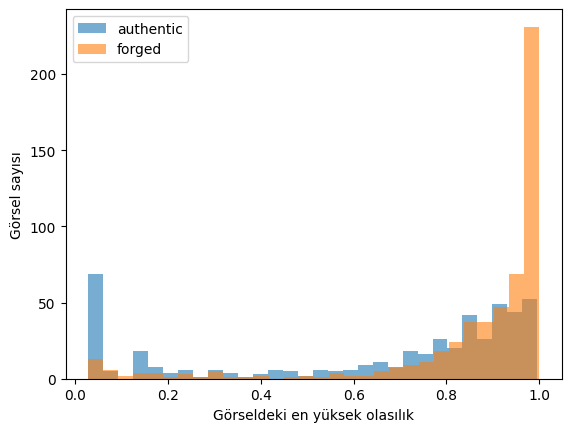

In [36]:
is_a = val_df.label.values == 0
max_p = probs.reshape(len(probs), -1).max(axis=1) / 255.0

plt.hist(max_p[is_a], bins=30, alpha=0.6, label="authentic")
plt.hist(max_p[~is_a], bins=30, alpha=0.6, label="forged")
plt.xlabel("Görseldeki en yüksek olasılık"); plt.ylabel("Görsel sayısı")
plt.legend(); plt.show()

In [35]:
print("en yüksek olasılık ≥ 0.97 olan görsel oranı:")
print("  authentic:", (max_p[is_a] >= 0.97).mean().round(2))
print("  forged   :", (max_p[~is_a] >= 0.97).mean().round(2))
print("en yüksek olasılık < 0.3 olan görsel oranı:")
print("  authentic:", (max_p[is_a] < 0.3).mean().round(2))
print("  forged   :", (max_p[~is_a] < 0.3).mean().round(2))

en yüksek olasılık ≥ 0.97 olan görsel oranı:
  authentic: 0.08
  forged   : 0.39
en yüksek olasılık < 0.3 olan görsel oranı:
  authentic: 0.24
  forged   : 0.07


**Gözlem:** Sahte görsellerin %49'unda en yüksek olasılık 0.97 ve üzerinde; authentic görsellerde bu oran %19. Düşük olasılık tarafında (< 0.3) ise authentic görsellerin %24'ü, sahte görsellerin yalnızca %5'i yer alıyor. Olasılıklar büyük ölçüde 0 ya da 1 civarında toplanıyor; ara değerler (0.4-0.8) iki sınıfta da seyrek ve birbirine karışmış durumda.

**Sonuç:** Model sahte görsellerde yüksek güvenli bölgeler üretme eğiliminde, ancak authentic görsellerin yaklaşık beşte birinde de aynı şeyi yapıyor. Dolayısıyla "görseldeki en yüksek olasılık" tek başına güvenilir bir authentic/forged ayırıcı
değil: 0.97 eşiği sahtelerin yarısını yakalarken authentic görsellerin %19'unda yanlış alarm üretir. Authentic bir görselde tek bir yanlış maske o görselin skorunu sıfırladığı için bu yanlış alarm oranı yarışma metriğinde belirleyici. Olasılıklar
doygun olduğundan piksel eşiği (`thr`) ve bileşen güven eşiği (`min_score`) sınırlı etki yapacak; bileşen alanına dayalı filtrenin (`min_area_frac`) etkisi ayrıca denenecek.

#### Son işleme ayarlarının seçimi
Modelin olasılık haritaları üç ayarla instance maskelerine dönüştürülür: piksel eşiği (`thr`), bir bileşenin geçerli sayılması için gereken minimum alan (`min_area_frac`,
görsel alanının oranı) ve bileşen içi ortalama olasılık eşiği (`min_score`). Ayarlar, validation setinin yarısında (ayar yarısı) ızgara araması ile seçildi; sonuçlar ayar
yapılmayan diğer yarıda raporlanacaktır.

In [ ]:
import itertools
from sklearn.model_selection import train_test_split

idx = np.arange(len(val_df))
tune_idx, rep_idx = train_test_split(idx, test_size=0.5,
                                     stratify=val_df.label.values, random_state=42)
is_t = val_df.label.values[tune_idx] == 0

cache = {}
rows = []
for thr, maf, ms in itertools.product([0.5, 0.9], [0.001, 0.005, 0.01, 0.02, 0.05], [0.5, 0.9]):
    s, per = score_probs(val_df, probs, sizes, idx=tune_idx, gt_cache=cache,
                         return_per_image=True, thr=thr, min_area_frac=maf, min_score=ms)
    rows.append({"thr": thr, "min_area_frac": maf, "min_score": ms, "genel": s,
                 "authentic": per[is_t].mean(), "sahte": per[~is_t].mean()})

grid = pd.DataFrame(rows).sort_values("genel", ascending=False).round(3)
print(grid.head(8).to_string(index=False))

 thr  min_area_frac  min_score  genel  authentic  sahte
 0.5          0.001        0.9  0.534      0.979  0.149
 0.9          0.005        0.9  0.508      0.971  0.108
 0.9          0.005        0.5  0.508      0.971  0.108
 0.5          0.005        0.9  0.508      0.992  0.089
 0.9          0.001        0.5  0.504      0.891  0.168
 0.9          0.001        0.9  0.504      0.891  0.168
 0.9          0.010        0.9  0.502      0.979  0.089
 0.9          0.010        0.5  0.502      0.979  0.089


In [32]:
rows = []
for thr, maf, ms in itertools.product([0.5, 0.7], [0.0002, 0.0005, 0.001], [0.9, 0.95, 0.98]):
    s, per = score_probs(val_df, probs, sizes, idx=tune_idx, gt_cache=cache,
                         return_per_image=True, thr=thr, min_area_frac=maf, min_score=ms)
    rows.append({"thr": thr, "min_area_frac": maf, "min_score": ms, "genel": s,
                 "authentic": per[is_t].mean(), "sahte": per[~is_t].mean()})

grid2 = pd.DataFrame(rows).sort_values("genel", ascending=False).round(3)
print(grid2.head(5).to_string(index=False))

 thr  min_area_frac  min_score  genel  authentic  sahte
 0.7          0.001        0.9  0.547      0.979  0.172
 0.5          0.001        0.9  0.534      0.979  0.149
 0.7          0.000        0.9  0.526      0.924  0.181
 0.7          0.000        0.9  0.522      0.916  0.182
 0.5          0.000        0.9  0.519      0.937  0.158


**Gözlem:** Alan eşiği büyüdükçe authentic skoru yükseliyor (0.924 → 1.000), sahte skoru düşüyor (0.168 → 0.060); genel skor bu dengeyle belirleniyor. İlk ızgarada en iyi ayar
ızgaranın kenarında kaldığı için aralık daha küçük alan eşiklerine ve daha yüksek güven eşiklerine genişletildi; aynı ayar yine en yüksek skoru verdi (thr=0.5,
min_area_frac=0.001, min_score=0.9, genel 0.519). Daha küçük alan eşikleri ve daha yüksek `min_score` değerleri iyileşme sağlamadı. thr=0.9 iken `min_score` sonucu değiştirmedi
(olasılıklar 0/1 civarında toplanıyor); thr=0.5'te ise güven filtresi yanlış alarmları azalttı.

**Sonuç:** Tüm ayarlar yaklaşık 0.49-0.52 aralığında kaldı ve Baseline 0'ın (≈0.46) üzerinde. Ayar yarısı ~513 görsel olduğundan 0.01-0.02'lik farklar anlamlı sayılmamalıdır;
bu nedenle thr=0.5, min_area_frac=0.001, min_score=0.9 ayarı seçildi.

In [33]:
params = dict(thr=0.5, min_area_frac=0.001, min_score=0.9)

s_unet, per_u = score_probs(val_df, probs, sizes, idx=rep_idx, return_per_image=True, **params)
is_r = val_df.label.values[rep_idx] == 0

print(f"U-Net      oF1: {s_unet:.3f} | authentic: {per_u[is_r].mean():.3f} | sahte: {per_u[~is_r].mean():.3f}")
print(f"SIFT       oF1: {per1[rep_idx].mean():.3f} | authentic: {per1[rep_idx][is_r].mean():.3f} | sahte: {per1[rep_idx][~is_r].mean():.3f}")
print(f"Baseline 0 oF1: {is_r.mean():.3f}")

U-Net      oF1: 0.528 | authentic: 0.975 | sahte: 0.142
SIFT       oF1: 0.542 | authentic: 0.971 | sahte: 0.172
Baseline 0 oF1: 0.464


### 4.5 Baseline karşılaştırması

Üç baseline, ayar yapılmayan validation yarısında (≈513 görsel) aynı oF1 metriğiyle
karşılaştırıldı.

| Yöntem | oF1 | Authentic | Sahte |
|---|---|---|---|
| Baseline 0: hepsi authentic | 0.464 | 1.000 | 0.000 |
| Baseline 1: SIFT + RANSAC | 0.542 | 0.971 | 0.172 |
| Baseline 2: U-Net (ResNet34) | 0.528 | 0.975 | 0.142 |

**Sonuç:** İki model de Baseline 0'ı geçti, ancak U-Net SIFT'i geçemedi. Sahte görsellerde ikisi de benzer skor aldı, fark authentic görsellerdeki yanlış alarm oranından kaynaklanıyor. Authentic bir görselde tek bir yanlış maske o görselin skorunu sıfırladığı için bu fark metrikte belirleyici.

**Yorum:** Her iki yöntem de sahte görsellerin çoğunu kaçırıyor; metrik, sahte görsellerde yüksek recall ve authentic görsellerde sıfır yanlış alarmı birlikte gerektirdiğinden problem baseline'lar için zor. U-Net'in SIFT'in gerisinde kalmasının olası nedenleri: eğitim loss'unun epoch 6'dan sonra kararsızlaşması, sabit öğrenme oranı ve kısa eğitim (8 epoch); bu nedenler denenmedi.

.csv çevirisi

In [37]:
os.makedirs("results", exist_ok=True)

summary = pd.DataFrame([
    {"yöntem": "Baseline 0", "oF1": is_r.mean(), "authentic": 1.0, "sahte": 0.0},
    {"yöntem": "SIFT + RANSAC", "oF1": per1[rep_idx].mean(),
     "authentic": per1[rep_idx][is_r].mean(), "sahte": per1[rep_idx][~is_r].mean()},
    {"yöntem": "U-Net", "oF1": s_unet,
     "authentic": per_u[is_r].mean(), "sahte": per_u[~is_r].mean()},
]).round(3)

summary.to_csv("results/summary.csv", index=False)
summary

,yöntem,oF1,authentic,sahte
0,Baseline 0,0.464,1.000,0.000
1,SIFT + RANSAC,0.542,0.971,0.172
2,U-Net,0.528,0.975,0.142
